# Project 12 — worker voice in platform governance
**Five research questions · descriptive secondary analysis · reproducible offline execution**

All 15 scores and all six Principle 4.1 award classifications were checked against the original 40-page English report on 10 November 2026 (Asia/Kolkata date). Overall scores: p. 11. Award list: p. 3, corroborated by the discussion on p. 13.

**Source:** Fairwork (2023), *Fairwork Cloudwork Ratings 2023: Work in the Planetary Labour Market*. [Report](https://fairwork.oii.ox.ac.uk/wp-content/uploads/sites/17/2023/07/Fairwork-Cloudwork-Ratings-2023-Red.pdf) · [Publication page](https://fairwork.oii.ox.ac.uk/en/fw/publications/fairwork-cloudwork-ratings-2023-work-in-the-planetary-labour-market/).

These are platform-level published ratings, not worker microdata or independently coded policies. Non-award means insufficient verified evidence to award the threshold; it is not proof that protection is absent. Principle 4.1 is part of the total score, so RQ3 and RQ5 cannot establish an independent association or causal effect. Bands are researcher-defined.

**Execution:** The companion executed notebook records a fresh sequential local Python run with captured tables and figures. A new Kaggle run and saved version remain to be completed in the user’s account.

## Research questions
**RQ1.** How do overall Fairwork scores vary across the 15 cloudwork platforms assessed in 2023?

**RQ2.** What proportion of the 15 platforms received the Fairwork Principle 4.1 due-process award?

**RQ3.** How do overall Fairwork scores differ descriptively between platforms that received the Principle 4.1 award and those that did not?

**RQ4.** How are the 15 platforms distributed across different overall Fairwork score levels (low, middle, and high)?

**RQ5.** How does the distribution of Principle 4.1 awards vary across those overall Fairwork score levels?

**Pre-specified descriptive bands for RQ4–RQ5:** low = 0–2, middle = 3–5, high = 6–10 points. These bands are researcher-defined, not official Fairwork classifications. They are descriptive only.

In [1]:
from pathlib import Path
import hashlib, json, platform, sys, zipfile
from datetime import datetime, timezone
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

OUT = Path('/kaggle/working/project12_fairwork_5rqs') if Path('/kaggle/working').exists() else Path.cwd() / 'project12_fairwork_5rqs'
OUT.mkdir(parents=True, exist_ok=True)
RUN_STARTED_UTC = datetime.now(timezone.utc).isoformat()
SOURCE_URL = 'https://fairwork.oii.ox.ac.uk/wp-content/uploads/sites/17/2023/07/Fairwork-Cloudwork-Ratings-2023-Red.pdf'
SOURCE_SHA256 = 'd1fecc0d7f39cc523f471c49895c6f86572045bc015215a3654437969424316b'
ENVIRONMENT = {'python': platform.python_version(), **{name: version(name) for name in ['numpy', 'pandas', 'matplotlib', 'ipython']}}
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
print('Results folder:', OUT)
print('Environment:', ENVIRONMENT)


Results folder: /workspace/scratch/5b46aaa1b5f3/output/Project12_Professor_Submission/notebooks/project12_fairwork_5rqs
Environment: {'python': '3.12.14', 'numpy': '2.3.5', 'pandas': '2.2.3', 'matplotlib': '3.10.8', 'ipython': '9.16.1'}


In [2]:
# Transcription checked against the Fairwork Cloudwork Ratings 2023 report.
# Source page 11: overall scores. Pages 2–3 and 13: six Principle 4.1 awards.
rows = [
 ('ComeUp',5,1),('Prolific',5,0),('Terawork',5,1),('Appen',3,0),
 ('SoyFreelancer',2,1),('Upwork',2,0),('Clickworker',1,0),
 ('Elharefa',1,1),('Fiverr',1,1),('PeoplePerHour',1,1),
 ('Scale/Remotasks',1,0),('Amazon MTurk',0,0),('Freelancer',0,0),
 ('Microworkers',0,0),('Workana',0,0)
]
df = pd.DataFrame(rows, columns=['platform','fairwork_2023_score_out_of_10','fairwork_2023_threshold_4_1'])
df['due_process_award_status'] = df['fairwork_2023_threshold_4_1'].map({1:'Awarded',0:'Not awarded'})
df['source_page_scores'] = 11
df['source_page_awards'] = 3
df['source_report_url'] = SOURCE_URL
df['score_band'] = pd.cut(df['fairwork_2023_score_out_of_10'],bins=[-0.5,2.5,5.5,10.5],labels=['Low (0–2)','Middle (3–5)','High (6–10)'],ordered=True)
assert len(df)==15 and df.platform.is_unique
assert not df.isna().any().any()
assert df.fairwork_2023_score_out_of_10.mod(1).eq(0).all()
assert df.fairwork_2023_threshold_4_1.isin([0, 1]).all()
assert df.fairwork_2023_score_out_of_10.ge(df.fairwork_2023_threshold_4_1).all()
assert df.fairwork_2023_score_out_of_10.between(0,10).all()
assert df.fairwork_2023_threshold_4_1.sum()==6
assert df.fairwork_2023_score_out_of_10.sum()==27
assert set(df.loc[df.fairwork_2023_threshold_4_1.eq(1),'platform']) == {'ComeUp','Terawork','SoyFreelancer','Elharefa','Fiverr','PeoplePerHour'}
df.to_csv(OUT/'table_1_platform_level_data.csv',index=False)
display(df)


,platform,fairwork_2023_score_out_of_10,fairwork_2023_threshold_4_1,due_process_award_status,source_page_scores,source_page_awards,source_report_url,score_band
0,ComeUp,5,1,Awarded,11,3,https://fairwork.oii.ox.ac.uk/wp-content/uploa...,Middle (3–5)
1,Prolific,5,0,Not awarded,11,3,https://fairwork.oii.ox.ac.uk/wp-content/uploa...,Middle (3–5)
2,Terawork,5,1,Awarded,11,3,https://fairwork.oii.ox.ac.uk/wp-content/uploa...,Middle (3–5)
3,Appen,3,0,Not awarded,11,3,https://fairwork.oii.ox.ac.uk/wp-content/uploa...,Middle (3–5)
4,SoyFreelancer,2,1,Awarded,11,3,https://fairwork.oii.ox.ac.uk/wp-content/uploa...,Low (0–2)
5,Upwork,2,0,Not awarded,11,3,https://fairwork.oii.ox.ac.uk/wp-content/uploa...,Low (0–2)
6,Clickworker,1,0,Not awarded,11,3,https://fairwork.oii.ox.ac.uk/wp-content/uploa...,Low (0–2)
7,Elharefa,1,1,Awarded,11,3,https://fairwork.oii.ox.ac.uk/wp-content/uploa...,Low (0–2)
8,Fiverr,1,1,Awarded,11,3,https://fairwork.oii.ox.ac.uk/wp-content/uploa...,Low (0–2)
9,PeoplePerHour,1,1,Awarded,11,3,https://fairwork.oii.ox.ac.uk/wp-content/uploa...,Low (0–2)


## RQ1 — Score variation across 15 platforms

,n_platforms,mean,median,sample_sd,min,max
0,15,1.8,1.0,1.859339,0,5


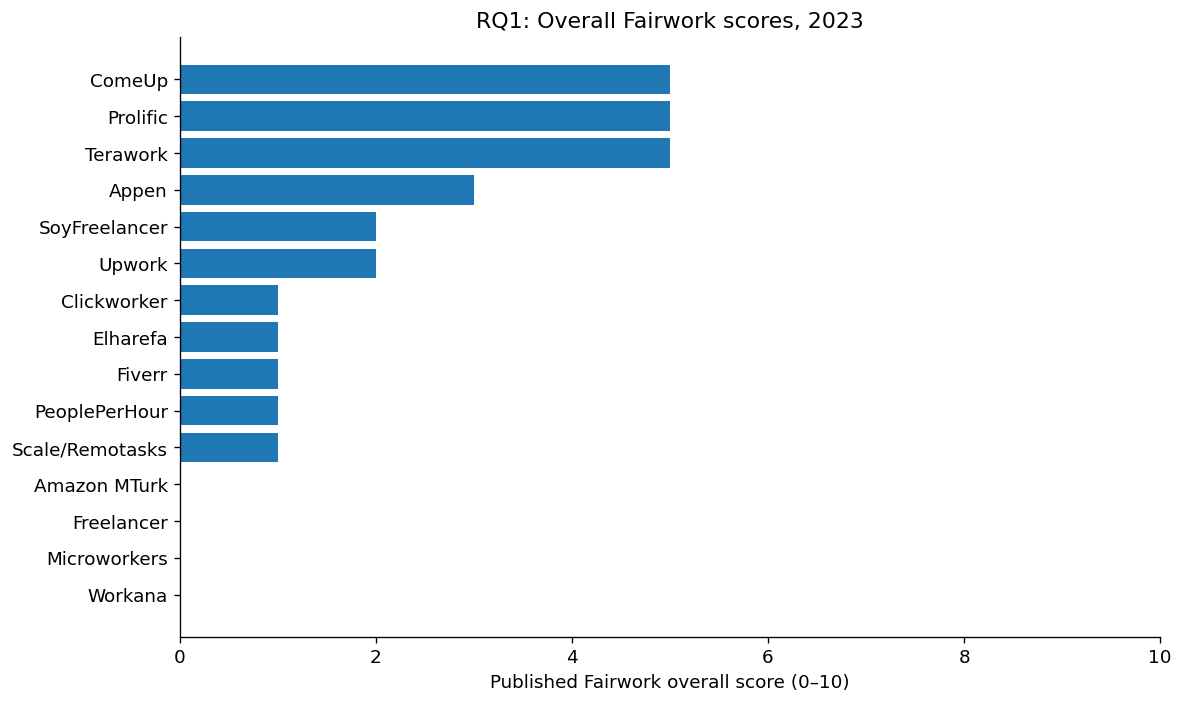

In [3]:
s = df['fairwork_2023_score_out_of_10']
rq1 = pd.DataFrame([{'n_platforms':len(df),'mean':s.mean(),'median':s.median(),'sample_sd':s.std(ddof=1),'min':s.min(),'max':s.max()}])
rq1.to_csv(OUT/'table_2_rq1_score_summary.csv',index=False)
display(rq1)
ranked=df.sort_values(['fairwork_2023_score_out_of_10','platform'],ascending=[False,True])
fig,ax=plt.subplots(figsize=(10,6))
ax.barh(ranked.platform[::-1],ranked.fairwork_2023_score_out_of_10[::-1]);ax.set_xlim(0,10)
ax.set_xlabel('Published Fairwork overall score (0–10)');ax.set_title('RQ1: Overall Fairwork scores, 2023')
fig.tight_layout();fig.savefig(OUT/'figure_1_rq1_platform_scores.png',dpi=300);plt.show()


## RQ2 — Principle 4.1 award prevalence

,due_process_award_status,n_platforms,percent
0,Awarded,6,40.0
1,Not awarded,9,60.0


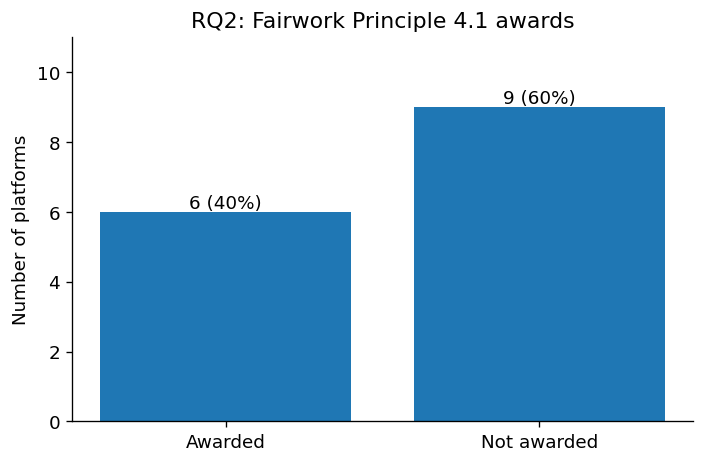

In [4]:
rq2 = (df.groupby('due_process_award_status').size().reindex(['Awarded','Not awarded'],fill_value=0).rename('n_platforms').reset_index())
rq2['percent']=100*rq2.n_platforms/len(df)
rq2.to_csv(OUT/'table_3_rq2_awards.csv',index=False)
display(rq2)
fig,ax=plt.subplots(figsize=(6,4));ax.bar(rq2.due_process_award_status,rq2.n_platforms)
ax.set_ylabel('Number of platforms');ax.set_title('RQ2: Fairwork Principle 4.1 awards')
for i,v in enumerate(rq2.n_platforms):ax.text(i,v+0.1,f'{v} ({rq2.percent.iloc[i]:.0f}%)',ha='center')
ax.set_ylim(0,11);fig.tight_layout();fig.savefig(OUT/'figure_2_rq2_awards.png',dpi=300);plt.show()


## RQ3 — Descriptive score differences by award status

,due_process_award_status,count,mean,median,min,max
0,Awarded,6,2.500000,1.5,1,5
1,Not awarded,9,1.333333,1.0,0,5


Descriptive difference in means (awarded minus not awarded): 1.167


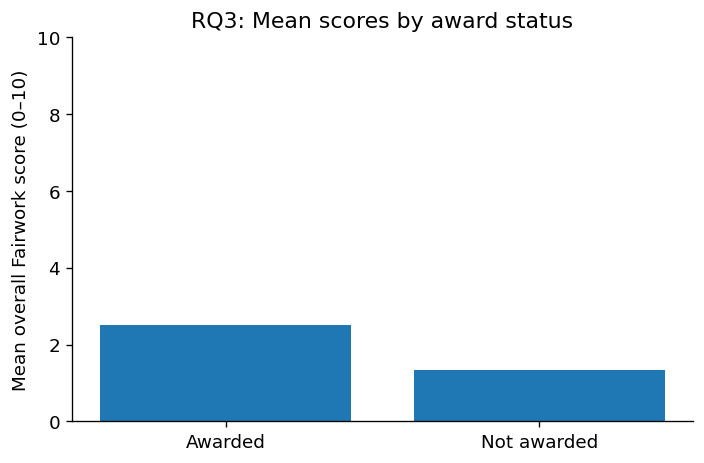

CAUTION: Principle 4.1 is a component of the overall score; this comparison is not an independent association.


In [5]:
rq3=(df.groupby('due_process_award_status',observed=True)['fairwork_2023_score_out_of_10'].agg(['count','mean','median','min','max']).reindex(['Awarded','Not awarded']).reset_index())
rq3.to_csv(OUT/'table_4_rq3_scores_by_award.csv',index=False)
display(rq3)
print('Descriptive difference in means (awarded minus not awarded):',round(rq3['mean'].iloc[0]-rq3['mean'].iloc[1],3))
fig,ax=plt.subplots(figsize=(6,4));ax.bar(rq3.due_process_award_status,rq3['mean'])
ax.set_ylabel('Mean overall Fairwork score (0–10)');ax.set_title('RQ3: Mean scores by award status')
ax.set_ylim(0,10);fig.tight_layout();fig.savefig(OUT/'figure_3_rq3_group_means.png',dpi=300);plt.show()
print('CAUTION: Principle 4.1 is a component of the overall score; this comparison is not an independent association.')


## RQ4 — Distribution across researcher-defined score bands

,score_band,n_platforms,percent
0,Low (0–2),11,73.333333
1,Middle (3–5),4,26.666667
2,High (6–10),0,0.000000


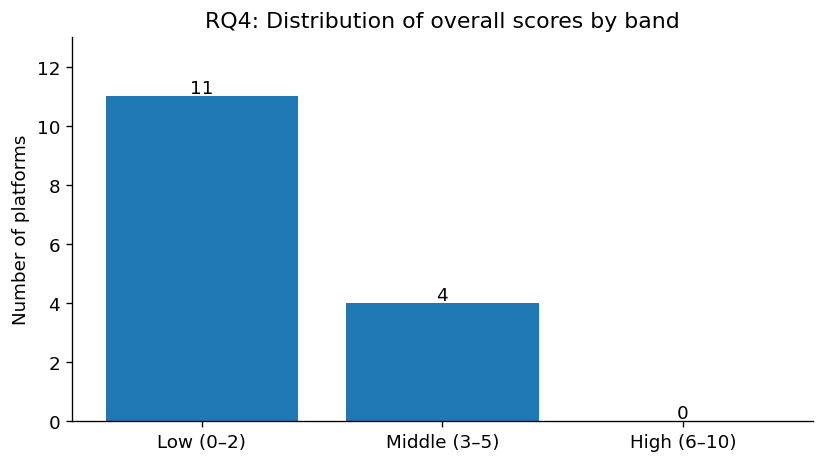

In [6]:
bands=['Low (0–2)','Middle (3–5)','High (6–10)']
rq4=(df.groupby('score_band',observed=False).size().reindex(bands,fill_value=0).rename('n_platforms').reset_index())
rq4['percent']=100*rq4.n_platforms/len(df)
rq4.to_csv(OUT/'table_5_rq4_score_bands.csv',index=False)
display(rq4)
fig,ax=plt.subplots(figsize=(7,4));ax.bar(rq4.score_band.astype(str),rq4.n_platforms)
ax.set_ylabel('Number of platforms');ax.set_title('RQ4: Distribution of overall scores by band')
for i,v in enumerate(rq4.n_platforms):ax.text(i,v+0.1,str(v),ha='center')
ax.set_ylim(0,max(rq4.n_platforms)+2);fig.tight_layout();fig.savefig(OUT/'figure_4_rq4_score_bands.png',dpi=300);plt.show()


## RQ5 — Principle 4.1 awards within each score band

due_process_award_status,Awarded,Not awarded,total,awarded_percent_within_band
score_band,,,,
Low (0–2),4,7,11,36.363636
Middle (3–5),2,2,4,50.000000
High (6–10),0,0,0,NaN


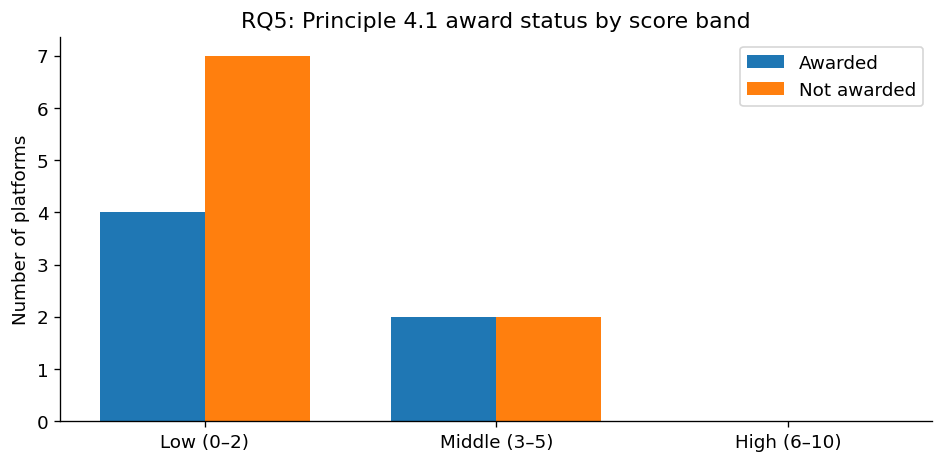

CAUTION: Empty high-score band; its award rate is undefined, not 0%.


In [7]:
rq5=pd.crosstab(df.score_band,df.due_process_award_status).reindex(index=bands,columns=['Awarded','Not awarded'],fill_value=0)
rq5['total']=rq5.sum(axis=1)
rq5['awarded_percent_within_band'] = 100 * rq5['Awarded'] / rq5['total'].replace(0, np.nan)
rq5.index.name='score_band'
rq5.reset_index().to_csv(OUT/'table_6_rq5_awards_by_band.csv',index=False)
display(rq5)
fig,ax=plt.subplots(figsize=(8,4));x=np.arange(len(bands));w=.36
ax.bar(x-w/2,rq5['Awarded'],width=w,label='Awarded');ax.bar(x+w/2,rq5['Not awarded'],width=w,label='Not awarded')
ax.set_xticks(x,bands);ax.set_ylabel('Number of platforms');ax.set_title('RQ5: Principle 4.1 award status by score band');ax.legend()
fig.tight_layout();fig.savefig(OUT/'figure_5_rq5_awards_by_band.png',dpi=300);plt.show()
print('CAUTION: Empty high-score band; its award rate is undefined, not 0%.')


## Validation, interpretation limits, and export

In [8]:
# Reconcile every research question and explicitly preserve the empty-band result.
assert rq2.n_platforms.sum() == 15 and rq4.n_platforms.sum() == 15
assert rq5['total'].sum() == 15 and rq5['Awarded'].sum() == 6
assert np.isclose(rq1['mean'].iloc[0], 1.8)
assert np.isclose(rq1['sample_sd'].iloc[0], np.std([5,5,5,3,2,2,1,1,1,1,1,0,0,0,0], ddof=1))
assert np.isclose(rq3['mean'].iloc[0], 2.5)
assert np.isclose(rq3['mean'].iloc[1], 12/9)
assert np.isclose(rq2['percent'].sum(), 100)
assert np.isclose(rq4['percent'].sum(), 100)
assert rq4['n_platforms'].tolist() == [11, 4, 0]
assert rq5[['Awarded', 'Not awarded']].to_numpy().tolist() == [[4, 7], [2, 2], [0, 0]]
assert pd.isna(rq5.loc['High (6–10)', 'awarded_percent_within_band'])

expected_csv = ['table_1_platform_level_data.csv', 'table_2_rq1_score_summary.csv',
                'table_3_rq2_awards.csv', 'table_4_rq3_scores_by_award.csv',
                'table_5_rq4_score_bands.csv', 'table_6_rq5_awards_by_band.csv']
expected_png = ['figure_1_rq1_platform_scores.png', 'figure_2_rq2_awards.png',
                'figure_3_rq3_group_means.png', 'figure_4_rq4_score_bands.png',
                'figure_5_rq5_awards_by_band.png']
for name in expected_csv + expected_png:
    assert (OUT / name).is_file() and (OUT / name).stat().st_size > 0
# Confirm that the exported CSVs reproduce the in-memory results.
assert len(pd.read_csv(OUT / expected_csv[0])) == 15
assert np.isclose(pd.read_csv(OUT / expected_csv[1])['mean'].iloc[0], 1.8)
assert pd.isna(pd.read_csv(OUT / expected_csv[5])['awarded_percent_within_band'].iloc[2])
manifest = {
    'study': 'Project 12: secondary descriptive analysis of Fairwork Cloudwork Ratings 2023',
    'run_started_utc': RUN_STARTED_UTC,
    'run_finished_utc': datetime.now(timezone.utc).isoformat(),
    'execution_environment': ENVIRONMENT,
    'execution_platform': 'Kaggle' if Path('/kaggle/working').exists() else 'local Python',
    'source': {'title': 'Fairwork Cloudwork Ratings 2023: Work in the Planetary Labour Market',
               'url': SOURCE_URL, 'sha256_of_audited_report': SOURCE_SHA256,
               'report_pages': 40, 'scores_page': 11, 'awards_page': 3, 'awards_discussion_page': 13,
               'audit_date_asia_kolkata': '2026-11-10'},
    'platforms': 15, 'principle_4_1_awards': 6, 'research_questions': 5,
    'bands': {'low': '0–2', 'middle': '3–5', 'high': '6–10'},
    'limitations': ['All 15 purposively selected platforms in the 2023 report, one year',
                    'Researcher-defined bands, not official Fairwork categories',
                    'Principle 4.1 contributes to the total score',
                    'No worker-level inference, hypothesis test, or causal estimate',
                    'Non-award is not proof that due process is absent',
                    'Empty high band has an undefined within-band award rate'],
    'validation': 'PASS',
    'output_files': expected_csv + expected_png,
    'sha256': {name: hashlib.sha256((OUT / name).read_bytes()).hexdigest() for name in expected_csv + expected_png},
}
(OUT / 'analysis_manifest.json').write_text(json.dumps(manifest, indent=2, ensure_ascii=False) + '\n', encoding='utf-8')
archive = OUT.parent / 'Project12_Fairwork_2023_All_5_RQs_Results.zip'
# Export only this run's declared files; never include stale files from earlier runs.
with zipfile.ZipFile(archive, 'w', zipfile.ZIP_DEFLATED) as z:
    for name in expected_csv + expected_png + ['analysis_manifest.json']:
        z.write(OUT / name, arcname='results/' + name)
print('PASS: All 5 RQs computed; 15 platforms; 6 awards; six CSVs; five figures; manifest.')
print('Results ZIP:', archive)
print('Publication assessment: descriptive analysis complete; Journal of Business Research submission readiness not established.')


PASS: All 5 RQs computed; 15 platforms; 6 awards; six CSVs; five figures; manifest.
Results ZIP: /workspace/scratch/5b46aaa1b5f3/output/Project12_Professor_Submission/notebooks/Project12_Fairwork_2023_All_5_RQs_Results.zip
Publication assessment: descriptive analysis complete; Journal of Business Research submission readiness not established.


## Interpretation and submission status
The run answers RQ1–RQ5 for the 15 platforms in the 2023 report. The sample SD describes dispersion among those platforms; it is not a population uncertainty estimate. The empty high band has an undefined award rate.

The six awards and 15 scores are verified against the cited report, but the report’s underlying primary evidence is not reanalysed. The local run establishes computational reproducibility for these inputs. It does not certify journal acceptance, theoretical novelty, effectiveness of due process, worker outcomes, or a new Kaggle execution.

For submission, execute all cells on Kaggle, save the executed version, inspect and download its outputs, and record the actual notebook URL. Follow your institution’s AI-use disclosure requirements.

## Supplement: arithmetic overlap and platform influence
Adjusted score = overall score − threshold 4.1 award. The theoretical adjusted scale is 0–9. The original score bands are retained only in the original descriptive analysis; no independent award-by-band relationship is claimed. The leave-one-out analysis is an influence diagnostic, not a confidence interval.

,n,original_mean_out_of_10,adjusted_mean_out_of_9,adjusted_median,adjusted_sample_sd,adjusted_min,adjusted_max
award_status,,,,,,,
0,9,1.333333,1.333333,1.0,1.732051,0,5
1,6,2.500000,1.500000,0.5,1.974842,0,4


,quantity,value
0,original_gap_points,1.166667
1,direct_component_contribution_points,1.000000
2,remaining_gap_points,0.166667
3,direct_component_share_of_original_gap_percent,85.714286


,omitted_platform,omitted_award_status,remaining_n,adjusted_gap_after_omission
0,ComeUp,1,14,-0.333333
1,Prolific,0,14,0.625000
2,Terawork,1,14,-0.333333
3,Appen,0,14,0.375000
4,SoyFreelancer,1,14,0.266667
5,Upwork,0,14,0.250000
6,Clickworker,0,14,0.125000
7,Elharefa,1,14,0.466667
8,Fiverr,1,14,0.466667
9,PeoplePerHour,1,14,0.466667


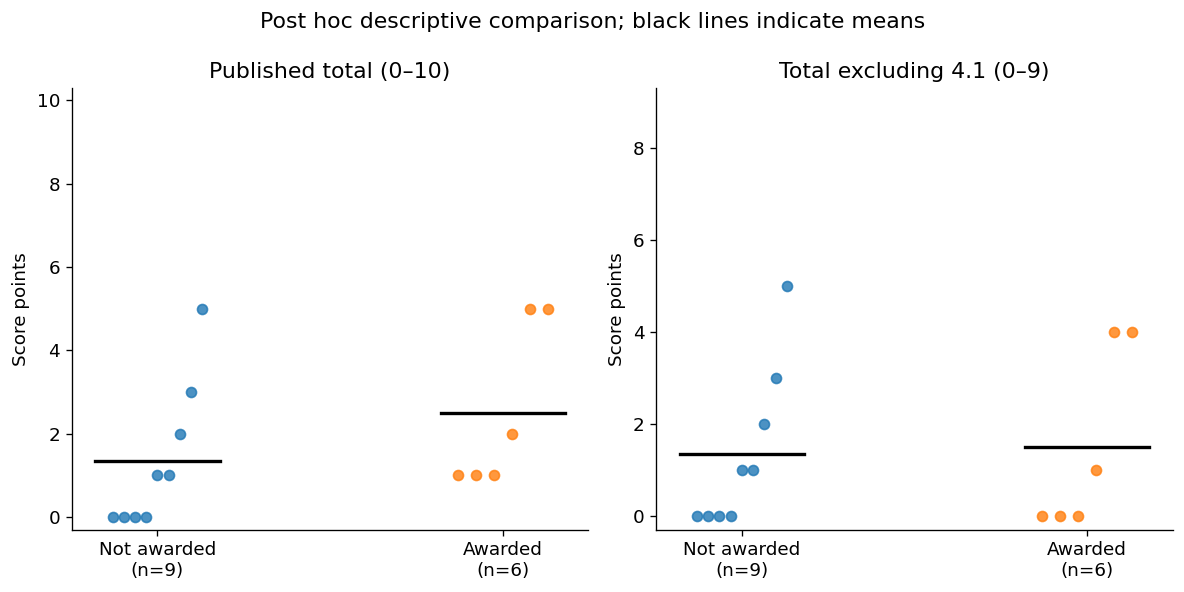

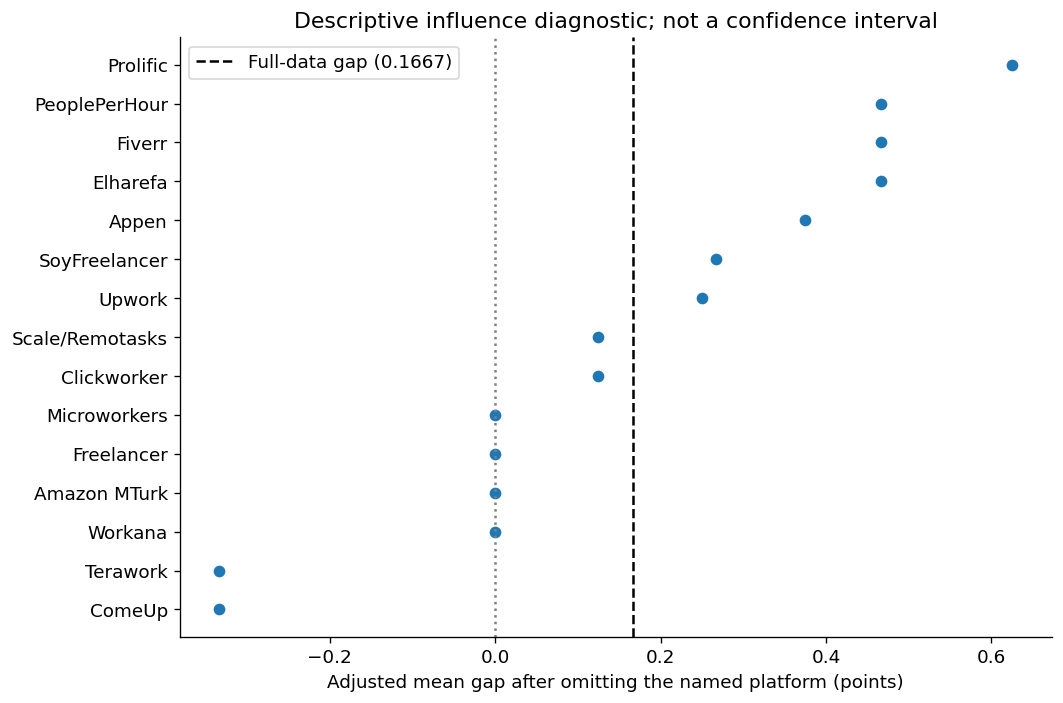

{
  "status": "PASS",
  "original_gap": 1.1666666666666667,
  "component_excluded_gap": 0.16666666666666674,
  "direct_component_share_percent": 85.71428571428571,
  "leave_one_out_min": -0.33333333333333326,
  "leave_one_out_max": 0.625
}


In [9]:
"""Post hoc descriptive sensitivity analysis; no causal or population inference.

Run after analysis.py, or use the combined notebook. No additional source data.
"""
from pathlib import Path
import hashlib
import json
import platform
from datetime import datetime, timezone
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

BASE = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path.cwd()
OUT_REPAIR = BASE / 'repair_outputs'
OUT_REPAIR.mkdir(exist_ok=True)
source = BASE / 'project12_fairwork_5rqs/table_1_platform_level_data.csv'
data = pd.read_csv(source)
score = 'fairwork_2023_score_out_of_10'
award = 'fairwork_2023_threshold_4_1'
assert len(data) == 15 and data.platform.is_unique
assert data[award].isin([0, 1]).all()
assert data[score].between(0, 10).all() and data[score].mod(1).eq(0).all()
data['score_excluding_4_1_out_of_9'] = data[score] - data[award]
adjusted = 'score_excluding_4_1_out_of_9'
assert data[adjusted].between(0, 9).all()
data.to_csv(OUT_REPAIR/'table_S1_component_excluded_data.csv', index=False)

summaries = []
for status, group in data.groupby(award):
    summaries.append({'award_status': int(status), 'n': len(group),
                      'original_mean_out_of_10': group[score].mean(),
                      'adjusted_mean_out_of_9': group[adjusted].mean(),
                      'adjusted_median': group[adjusted].median(),
                      'adjusted_sample_sd': group[adjusted].std(ddof=1),
                      'adjusted_min': group[adjusted].min(),
                      'adjusted_max': group[adjusted].max()})
summary = pd.DataFrame(summaries).set_index('award_status')
original_gap = summary.loc[1,'original_mean_out_of_10'] - summary.loc[0,'original_mean_out_of_10']
adjusted_gap = summary.loc[1,'adjusted_mean_out_of_9'] - summary.loc[0,'adjusted_mean_out_of_9']
decomposition = pd.DataFrame([
    {'quantity':'original_gap_points', 'value':original_gap},
    {'quantity':'direct_component_contribution_points', 'value':original_gap-adjusted_gap},
    {'quantity':'remaining_gap_points', 'value':adjusted_gap},
    {'quantity':'direct_component_share_of_original_gap_percent', 'value':100*(original_gap-adjusted_gap)/original_gap}
])
summary.to_csv(OUT_REPAIR/'table_S2_adjusted_group_summary.csv')
decomposition.to_csv(OUT_REPAIR/'table_S3_gap_decomposition.csv', index=False)
display(summary)
display(decomposition)

# Leave-one-platform-out is a descriptive influence diagnostic, not a confidence interval.
influence = []
for index, row in data.iterrows():
    reduced = data.drop(index)
    means = reduced.groupby(award)[adjusted].mean()
    influence.append({'omitted_platform':row.platform,
                      'omitted_award_status':int(row[award]),
                      'remaining_n':len(reduced),
                      'adjusted_gap_after_omission':means.loc[1]-means.loc[0]})
influence = pd.DataFrame(influence)
influence.to_csv(OUT_REPAIR/'table_S4_leave_one_platform_out.csv', index=False)
display(influence)

# Independently reconcile with explicit group arithmetic and a plain Python loop.
assert np.isclose(original_gap, 7/6)
assert np.isclose(adjusted_gap, 1/6)
assert np.isclose(summary.loc[1,'adjusted_mean_out_of_9'], 9/6)
assert np.isclose(summary.loc[0,'adjusted_mean_out_of_9'], 12/9)
assert np.isclose(original_gap-adjusted_gap, 1)
for result in influence.itertuples():
    remaining = [r for r in data.to_dict('records') if r['platform'] != result.omitted_platform]
    a = [r[score]-r[award] for r in remaining if r[award] == 1]
    b = [r[score]-r[award] for r in remaining if r[award] == 0]
    assert np.isclose(result.adjusted_gap_after_omission, sum(a)/len(a)-sum(b)/len(b))

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, field, title, ymax in [(axes[0], score, 'Published total (0–10)', 10),
                               (axes[1], adjusted, 'Total excluding 4.1 (0–9)', 9)]:
    for status in [0, 1]:
        values = data.loc[data[award].eq(status), field].sort_values().to_numpy()
        offsets = np.linspace(-0.13, 0.13, len(values))
        ax.scatter(status+offsets, values, alpha=.8)
        ax.plot([status-.18,status+.18], [values.mean(),values.mean()], color='black', linewidth=2)
    ax.set_xticks([0,1], ['Not awarded\n(n=9)', 'Awarded\n(n=6)'])
    ax.set_ylim(-.3, ymax+.3)
    ax.set_ylabel('Score points')
    ax.set_title(title)
fig.suptitle('Post hoc descriptive comparison; black lines indicate means')
fig.tight_layout()
fig.savefig(OUT_REPAIR/'figure_S1_component_exclusion.png', dpi=300)
plt.show()

fig, ax = plt.subplots(figsize=(9,6))
ordered = influence.sort_values('adjusted_gap_after_omission')
ax.scatter(ordered.adjusted_gap_after_omission, ordered.omitted_platform)
ax.axvline(0, color='gray', linestyle=':')
ax.axvline(adjusted_gap, color='black', linestyle='--', label='Full-data gap (0.1667)')
ax.set_xlabel('Adjusted mean gap after omitting the named platform (points)')
ax.set_title('Descriptive influence diagnostic; not a confidence interval')
ax.legend()
fig.tight_layout()
fig.savefig(OUT_REPAIR/'figure_S2_platform_influence.png', dpi=300)
plt.show()

files = sorted(p.name for p in OUT_REPAIR.iterdir() if p.suffix in ['.csv','.png'])
for filename in files:
    assert (OUT_REPAIR/filename).stat().st_size > 0
exported = pd.read_csv(OUT_REPAIR/'table_S2_adjusted_group_summary.csv').set_index('award_status')
assert np.isclose(exported.loc[1,'adjusted_mean_out_of_9']-exported.loc[0,'adjusted_mean_out_of_9'], adjusted_gap)
report = {
    'status':'PASS', 'run_finished_utc':datetime.now(timezone.utc).isoformat(),
    'design':'post hoc descriptive sensitivity analysis of the supplied 2023 dataset',
    'source_data_sha256':hashlib.sha256(source.read_bytes()).hexdigest(),
    'environment':{'python':platform.python_version(), **{x:version(x) for x in ['numpy','pandas','matplotlib','ipython']}},
    'original_gap':float(original_gap), 'component_excluded_gap':float(adjusted_gap),
    'direct_component_share_percent':float(100*(original_gap-adjusted_gap)/original_gap),
    'leave_one_out_min':float(influence.adjusted_gap_after_omission.min()),
    'leave_one_out_max':float(influence.adjusted_gap_after_omission.max()),
    'leave_one_out_negative_gaps':int(influence.adjusted_gap_after_omission.lt(0).sum()),
    'cautions':['Removing arithmetic overlap does not establish statistical independence or causality.',
                'Original score-band analysis remains descriptive and component-dependent.',
                'No new data, preregistration, full source re-audit, or Kaggle execution is claimed.',
                'No statistical equivalence or population inference is established.',
                'Leave-one-out extrema are not confidence bounds.'],
    'files_sha256':{n:hashlib.sha256((OUT_REPAIR/n).read_bytes()).hexdigest() for n in files},
    'journal_approval':'Not granted; editorial decision required'
}
(OUT_REPAIR/'repair_validation.json').write_text(json.dumps(report, indent=2)+'\n')
print(json.dumps({k:report[k] for k in ['status','original_gap','component_excluded_gap','direct_component_share_percent','leave_one_out_min','leave_one_out_max']}, indent=2))
